# 03 - U-Net Model Implementation

## Objective
Build a U-Net architecture using PyTorch for microscopy image denoising.

## Architecture
1. Encoder
2. Bottleneck
3. Decoder
4. Skip Connections
5. Complete U-Net Model

## Input and Output
- Input: Noisy microscopy image
- Target: Clean ground-truth microscopy image
- Output: Denoised microscopy image

In [4]:
import torch
import torch.nn as nn

# Create a sample batch
x = torch.randn(8, 1, 256, 256)

print("Input shape:", x.shape)

# Define convolution layer
conv = nn.Conv2d(
    in_channels=1,
    out_channels=16,
    kernel_size=3,
    stride=1,
    padding=1
)

# Apply convolution
output = conv(x)

print("Output shape:", output.shape)

Input shape: torch.Size([8, 1, 256, 256])
Output shape: torch.Size([8, 16, 256, 256])


In [5]:
# Define ReLU activation
relu = nn.ReLU()

# Apply ReLU to convolution output
activated_output = relu(output)

print("Before ReLU:")
print("Minimum:", output.min().item())
print("Maximum:", output.max().item())

print("\nAfter ReLU:")
print("Minimum:", activated_output.min().item())
print("Maximum:", activated_output.max().item())

print("Output shape:", activated_output.shape)

Before ReLU:
Minimum: -3.6315174102783203
Maximum: 3.7222695350646973

After ReLU:
Minimum: 0.0
Maximum: 3.7222695350646973
Output shape: torch.Size([8, 16, 256, 256])


In [6]:
# Define Max Pooling
pool = nn.MaxPool2d(
    kernel_size=2,
    stride=2
)

# Apply pooling after ReLU
pooled_output = pool(activated_output)

print("Before pooling:", activated_output.shape)
print("After pooling:", pooled_output.shape)

Before pooling: torch.Size([8, 16, 256, 256])
After pooling: torch.Size([8, 16, 128, 128])


In [7]:
# Define upsampling
upsample = nn.Upsample(
    scale_factor=2,
    mode="bilinear",
    align_corners=False
)

# Apply upsampling
upsampled_output = upsample(pooled_output)

print("Before upsampling:", pooled_output.shape)
print("After upsampling:", upsampled_output.shape)

Before upsampling: torch.Size([8, 16, 128, 128])
After upsampling: torch.Size([8, 16, 256, 256])


In [8]:
# Simulate encoder and decoder feature maps

encoder_features = torch.randn(8, 16, 256, 256)

decoder_features = torch.randn(8, 16, 256, 256)

# Concatenate along channel dimension
combined_features = torch.cat(
    [encoder_features, decoder_features],
    dim=1
)

print("Encoder shape:", encoder_features.shape)
print("Decoder shape:", decoder_features.shape)
print("Combined shape:", combined_features.shape)

Encoder shape: torch.Size([8, 16, 256, 256])
Decoder shape: torch.Size([8, 16, 256, 256])
Combined shape: torch.Size([8, 32, 256, 256])


In [9]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [10]:
double_conv = DoubleConv(1, 64)

x = torch.randn(8, 1, 256, 256)

output = double_conv(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([8, 1, 256, 256])
Output shape: torch.Size([8, 64, 256, 256])


In [11]:
class EncoderBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = DoubleConv(in_channels, out_channels)

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

    def forward(self, x):

        features = self.conv(x)

        pooled = self.pool(features)

        return features, pooled

In [12]:
encoder = EncoderBlock(1, 64)

x = torch.randn(8, 1, 256, 256)

features, pooled = encoder(x)

print("Input:", x.shape)
print("Encoder features:", features.shape)
print("Pooled output:", pooled.shape)

Input: torch.Size([8, 1, 256, 256])
Encoder features: torch.Size([8, 64, 256, 256])
Pooled output: torch.Size([8, 64, 128, 128])


In [13]:
class Bottleneck(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x):
        return self.conv(x)

In [14]:
bottleneck = Bottleneck(64, 128)

x = torch.randn(8, 64, 128, 128)

output = bottleneck(x)

print("Input shape:", x.shape)
print("Bottleneck output:", output.shape)

Input shape: torch.Size([8, 64, 128, 128])
Bottleneck output: torch.Size([8, 128, 128, 128])


In [15]:
class DecoderBlock(nn.Module):

    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            out_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        x = self.up(x)

        x = torch.cat([x, skip], dim=1)

        x = self.conv(x)

        return x

In [16]:
decoder = DecoderBlock(
    in_channels=128,
    skip_channels=64,
    out_channels=64
)

x = torch.randn(8, 128, 128, 128)

skip = torch.randn(8, 64, 256, 256)

output = decoder(x, skip)

print("Decoder input:", x.shape)
print("Skip connection:", skip.shape)
print("Decoder output:", output.shape)

Decoder input: torch.Size([8, 128, 128, 128])
Skip connection: torch.Size([8, 64, 256, 256])
Decoder output: torch.Size([8, 64, 256, 256])


In [17]:
class OutputLayer(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):
        return self.conv(x)

In [18]:
output_layer = OutputLayer(64, 1)

x = torch.randn(8, 64, 256, 256)

output = output_layer(x)

print("Input shape:", x.shape)
print("Final output shape:", output.shape)

Input shape: torch.Size([8, 64, 256, 256])
Final output shape: torch.Size([8, 1, 256, 256])


In [19]:
class UNet(nn.Module):

    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        # Encoder
        self.encoder1 = EncoderBlock(in_channels, 64)
        self.encoder2 = EncoderBlock(64, 128)
        self.encoder3 = EncoderBlock(128, 256)
        self.encoder4 = EncoderBlock(256, 512)

        # Bottleneck
        self.bottleneck = Bottleneck(512, 1024)

        # Decoder
        self.decoder4 = DecoderBlock(1024, 512, 512)
        self.decoder3 = DecoderBlock(512, 256, 256)
        self.decoder2 = DecoderBlock(256, 128, 128)
        self.decoder1 = DecoderBlock(128, 64, 64)

        # Final output
        self.output_layer = OutputLayer(64, out_channels)

    def forward(self, x):

        # Encoder
        skip1, x = self.encoder1(x)
        skip2, x = self.encoder2(x)
        skip3, x = self.encoder3(x)
        skip4, x = self.encoder4(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder with skip connections
        x = self.decoder4(x, skip4)
        x = self.decoder3(x, skip3)
        x = self.decoder2(x, skip2)
        x = self.decoder1(x, skip1)

        # Output
        return self.output_layer(x)

In [20]:
model = UNet(
    in_channels=1,
    out_channels=1
)

print(model)

UNet(
  (encoder1): EncoderBlock(
    (conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (encoder2): EncoderBlock(
    (conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (3): ReLU(inplace=True)
      )
    )
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (encoder3): EncoderBlock(
    (conv): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inpla

In [21]:
sample_input = torch.randn(2, 1, 256, 256)

with torch.no_grad():
    prediction = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", prediction.shape)

Input shape: torch.Size([2, 1, 256, 256])
Output shape: torch.Size([2, 1, 256, 256])


In [22]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 31,030,593
Trainable parameters: 31,030,593


## 6. Model Preparation

In this section, we will:
1. Select the available computation device (CPU/GPU).
2. Move the U-Net model to that device.
3. Connect the training and validation DataLoaders.
4. Verify that the model can process an actual microscopy image batch.

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

model = model.to(device)

Selected device: cuda


## 7. Connecting the Dataset

In this section, we will connect the preprocessed microscopy dataset
to our U-Net model using PyTorch DataLoaders.

In [24]:
import os
import pandas as pd
import numpy as np
import tifffile
from pathlib import Path

from torch.utils.data import Dataset, DataLoader

In [25]:
# Locate project root
candidates = [Path.cwd(), Path.cwd().parent]

project_root = next(
    p for p in candidates
    if (p / "outputs/splits").exists()
)

# Load dataset splits
train_df = pd.read_csv(project_root / "outputs/splits/train.csv")
val_df = pd.read_csv(project_root / "outputs/splits/validation.csv")
test_df = pd.read_csv(project_root / "outputs/splits/test.csv")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

StopIteration: 

In [ ]:
# Define image directories
base_path = project_root / "data" / "Archive" / "small_images"

noisy_path = base_path / "noisy"
gt_path = base_path / "gt"

# Reconstruct image paths
for df in [train_df, val_df, test_df]:
    df["noisy_path"] = df["filename"].apply(
        lambda name: str(noisy_path / name)
    )

    df["gt_path"] = df["filename"].apply(
        lambda name: str(gt_path / name)
    )

# Verify paths
print("First noisy image:")
print(train_df.iloc[0]["noisy_path"])

print("\nFirst ground-truth image:")
print(train_df.iloc[0]["gt_path"])

print("\nNoisy file exists:",
      os.path.exists(train_df.iloc[0]["noisy_path"]))

print("GT file exists:",
      os.path.exists(train_df.iloc[0]["gt_path"]))


First noisy image:
C:\Users\learn\Microscopy-Denoising\data\Archive\small_images\noisy\1881.tif

First ground-truth image:
C:\Users\learn\Microscopy-Denoising\data\Archive\small_images\gt\1881.tif

Noisy file exists: True
GT file exists: True


## 8. Creating the Custom PyTorch Dataset

Create a custom Dataset class to load paired noisy and ground-truth microscopy images.

In [ ]:

class MicroscopyDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

        self.noisy_scale = 78.0
        self.gt_scale = 2252.0

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load noisy and ground-truth images
        noisy_image = tifffile.imread(row["noisy_path"])
        gt_image = tifffile.imread(row["gt_path"])

        # Normalize images
        noisy_image = noisy_image.astype(np.float32) / self.noisy_scale
        gt_image = gt_image.astype(np.float32) / self.gt_scale

        # Add channel dimension
        noisy_image = np.expand_dims(noisy_image, axis=0)
        gt_image = np.expand_dims(gt_image, axis=0)

        # Convert to PyTorch tensors
        noisy_tensor = torch.from_numpy(noisy_image)
        gt_tensor = torch.from_numpy(gt_image)

        return noisy_tensor, gt_tensor


In [ ]:
# Create dataset object
train_dataset = MicroscopyDataset(train_df)

# Load first image pair
noisy_tensor, gt_tensor = train_dataset[0]

print("Noisy tensor shape:", noisy_tensor.shape)
print("GT tensor shape:", gt_tensor.shape)

print("Noisy tensor dtype:", noisy_tensor.dtype)
print("GT tensor dtype:", gt_tensor.dtype)

print("Noisy min/max:",
      noisy_tensor.min().item(),
      noisy_tensor.max().item())

print("GT min/max:",
      gt_tensor.min().item(),
      gt_tensor.max().item())

Noisy tensor shape: torch.Size([1, 256, 256])
GT tensor shape: torch.Size([1, 256, 256])
Noisy tensor dtype: torch.float32
GT tensor dtype: torch.float32
Noisy min/max: 0.0 1.3205127716064453
GT min/max: 0.05550621822476387 1.2078152894973755


## 9. Creating PyTorch DataLoaders

Create training, validation and testing DataLoaders to load microscopy image pairs in batches.

In [ ]:

# Create dataset objects
train_dataset = MicroscopyDataset(train_df)
val_dataset = MicroscopyDataset(val_df)
test_dataset = MicroscopyDataset(test_df)

# Define batch size
BATCH_SIZE = 2

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 860
Validation batches: 185
Testing batches: 185


In [ ]:
# Get one batch from training DataLoader
noisy_batch, gt_batch = next(iter(train_loader))

print("Noisy batch shape:", noisy_batch.shape)
print("GT batch shape:", gt_batch.shape)

print("Noisy batch dtype:", noisy_batch.dtype)
print("GT batch dtype:", gt_batch.dtype)

Noisy batch shape: torch.Size([2, 1, 256, 256])
GT batch shape: torch.Size([2, 1, 256, 256])
Noisy batch dtype: torch.float32
GT batch dtype: torch.float32


In [ ]:
# Pass actual microscopy batch through U-Net

model.eval()

with torch.no_grad():
    noisy_batch = noisy_batch.to(device)
    prediction = model(noisy_batch)

print("Input shape:", noisy_batch.shape)
print("Prediction shape:", prediction.shape)
print("Prediction dtype:", prediction.dtype)

Input shape: torch.Size([2, 1, 256, 256])
Prediction shape: torch.Size([2, 1, 256, 256])
Prediction dtype: torch.float32


## 10. Loss Function and Optimizer

Define the loss function and optimizer for training the U-Net model.

- Loss Function: L1 Loss
- Optimizer: Adam

In [ ]:
# Define loss function
criterion = nn.L1Loss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: L1Loss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## 11. Training Function

Implement the training loop to:
1. Process batches of noisy microscopy images.
2. Generate denoised predictions.
3. Calculate L1 loss.
4. Perform backpropagation.
5. Update model parameters using Adam.

In [ ]:

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0

    for noisy, gt in loader:

        noisy = noisy.to(device)
        gt = gt.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        prediction = model(noisy)

        # Calculate loss
        loss = criterion(prediction, gt)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(loader)

    return epoch_loss


## 12. Validation Function

Evaluate the model on validation data without updating its parameters.

In [ ]:

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0

    with torch.no_grad():

        for noisy, gt in loader:

            noisy = noisy.to(device)
            gt = gt.to(device)

            # Forward pass
            prediction = model(noisy)

            # Calculate validation loss
            loss = criterion(prediction, gt)

            running_loss += loss.item()

    epoch_loss = running_loss / len(loader)

    return epoch_loss


## 13. Training Configuration

Define the number of epochs, checkpoint directory and training settings.

In [ ]:

from pathlib import Path

# Training configuration
EPOCHS = 10
BATCH_SIZE = 2
LEARNING_RATE = 0.001

# Directory to save model checkpoints
checkpoint_dir = project_root / "outputs" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Checkpoint directory:", checkpoint_dir)


Epochs: 10
Batch size: 2
Learning rate: 0.001
Checkpoint directory: C:\Users\learn\Microscopy-Denoising\outputs\checkpoints


## 14. Initial Training Test

Test one training iteration to verify forward propagation, loss calculation, backpropagation and optimizer updates.

In [ ]:

# Take one batch
noisy, gt = next(iter(train_loader))

noisy = noisy.to(device)
gt = gt.to(device)

# Training mode
model.train()

# Reset gradients
optimizer.zero_grad()

# Forward pass
prediction = model(noisy)

# Calculate loss
loss = criterion(prediction, gt)

# Backpropagation
loss.backward()

# Update weights
optimizer.step()

print("Initial training loss:", loss.item())
print("One training iteration completed successfully!")


Initial training loss: 0.08105935156345367
One training iteration completed successfully!


In [ ]:
torch.save(
    model.state_dict(),
    checkpoint_dir / "unet_initial_test.pth"
)

print("Initial checkpoint saved successfully!")

Initial checkpoint saved successfully!


In [ ]:
print("Model exists:", "model" in globals())
print("Optimizer exists:", "optimizer" in globals())
print("Loss function exists:", "criterion" in globals())
print("Training loader exists:", "train_loader" in globals())
print("Validation loader exists:", "val_loader" in globals())
print("Device:", device if "device" in globals() else "Not defined")
print("Epochs:", EPOCHS if "EPOCHS" in globals() else "Not defined")

Model exists: True
Optimizer exists: True
Loss function exists: True
Training loader exists: True
Validation loader exists: True
Device: cpu
Epochs: 10


In [ ]:
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("Model parameters:",
      sum(p.numel() for p in model.parameters()))

print("Checkpoint exists:",
      (checkpoint_dir / "unet_initial_test.pth").exists())

Training batches: 860
Validation batches: 185
Model parameters: 31030593
Checkpoint exists: True


In [ ]:
import time

model.train()

start_time = time.time()

for batch_idx, (noisy, gt) in enumerate(train_loader):
    if batch_idx == 5:
        break

    noisy = noisy.to(device)
    gt = gt.to(device)

    optimizer.zero_grad()

    prediction = model(noisy)
    loss = criterion(prediction, gt)

    loss.backward()
    optimizer.step()

elapsed = time.time() - start_time

print("5 batches completed!")
print("Time taken:", round(elapsed, 2), "seconds")
print("Average time per batch:", round(elapsed / 5, 2), "seconds")
print("Estimated training time per epoch:",
      round((elapsed / 5) * len(train_loader) / 60, 2), "minutes")

5 batches completed!
Time taken: 32.77 seconds
Average time per batch: 6.55 seconds
Estimated training time per epoch: 93.94 minutes


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
import os

print("Dataset folder exists:",
      os.path.exists("/content/microscopy_data/small_images"))

print("Noisy folder exists:",
      os.path.exists("/content/microscopy_data/small_images/noisy"))

print("GT folder exists:",
      os.path.exists("/content/microscopy_data/small_images/gt"))

Dataset folder exists: False
Noisy folder exists: False
GT folder exists: False


In [3]:
import os

os.makedirs("/content/microscopy_data", exist_ok=True)

!wget -c "https://zenodo.org/records/15624741/files/Archive.zip?download=1" -O /content/Archive.zip

--2026-11-21 06:46:47--  https://zenodo.org/records/15624741/files/Archive.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.51.60, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 290061612 (277M) [application/octet-stream]
Saving to: ‘/content/Archive.zip’

/content/Archive.zi 100%[===================>] 276.62M  3.23MB/s    in 3m 11s  

2026-11-21 06:49:59 (1.45 MB/s) - ‘/content/Archive.zip’ saved [290061612/290061612]



In [26]:
import hashlib

file_path = "/content/Archive.zip"

md5 = hashlib.md5()

with open(file_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        md5.update(chunk)

print("MD5:", md5.hexdigest())

MD5: 6a268178418294bb86705fb925a6c532


In [27]:
import zipfile
from pathlib import Path

zip_path = "/content/Archive.zip"
extract_path = "/content/microscopy_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print("Extracted folders:")
print(list(Path(extract_path).iterdir()))

Extraction completed!
Extracted folders:
[PosixPath('/content/microscopy_data/large_images'), PosixPath('/content/microscopy_data/__MACOSX'), PosixPath('/content/microscopy_data/small_images')]


In [28]:
from pathlib import Path

base_dir = Path("/content/microscopy_data/small_images")

noisy_dir = base_dir / "noisy"
gt_dir = base_dir / "gt"

noisy_files = list(noisy_dir.glob("*.tif"))
gt_files = list(gt_dir.glob("*.tif"))

print("Noisy images:", len(noisy_files))
print("Ground truth images:", len(gt_files))

print("Noisy folder exists:", noisy_dir.exists())
print("GT folder exists:", gt_dir.exists())

print("Sample filename:", noisy_files[0].name if noisy_files else "None")


Noisy images: 2457
Ground truth images: 2457
Noisy folder exists: True
GT folder exists: True
Sample filename: 1857.tif


In [29]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/suyash-jaiswal-7/Microscopy-Denoising/main/outputs/splits"

train_df = pd.read_csv(f"{base_url}/train.csv")
val_df = pd.read_csv(f"{base_url}/validation.csv")
test_df = pd.read_csv(f"{base_url}/test.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain sample:")
print(train_df.head())

Train: 1719
Validation: 369
Test: 369

Train sample:
   filename
0  1881.tif
1  1907.tif
2  1764.tif
3  1198.tif
4  1561.tif


In [30]:
from pathlib import Path

noisy_dir = Path("/content/microscopy_data/small_images/noisy")
gt_dir = Path("/content/microscopy_data/small_images/gt")

for df in [train_df, val_df, test_df]:
    df["noisy_path"] = df["filename"].apply(
        lambda name: str(noisy_dir / name)
    )
    df["gt_path"] = df["filename"].apply(
        lambda name: str(gt_dir / name)
    )

print("Noisy path exists:",
      Path(train_df.iloc[0]["noisy_path"]).exists())

print("GT path exists:",
      Path(train_df.iloc[0]["gt_path"]).exists())

print("\nSample paths:")
print(train_df[["filename", "noisy_path", "gt_path"]].head())

Noisy path exists: True
GT path exists: True

Sample paths:
   filename                                         noisy_path  \
0  1881.tif  /content/microscopy_data/small_images/noisy/18...   
1  1907.tif  /content/microscopy_data/small_images/noisy/19...   
2  1764.tif  /content/microscopy_data/small_images/noisy/17...   
3  1198.tif  /content/microscopy_data/small_images/noisy/11...   
4  1561.tif  /content/microscopy_data/small_images/noisy/15...   

                                             gt_path  
0  /content/microscopy_data/small_images/gt/1881.tif  
1  /content/microscopy_data/small_images/gt/1907.tif  
2  /content/microscopy_data/small_images/gt/1764.tif  
3  /content/microscopy_data/small_images/gt/1198.tif  
4  /content/microscopy_data/small_images/gt/1561.tif  


In [31]:
import torch
from torch.utils.data import Dataset, DataLoader
import tifffile
import numpy as np

NOISY_SCALE = 78
GT_SCALE = 2252

class MicroscopyDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        noisy = tifffile.imread(row["noisy_path"])
        gt = tifffile.imread(row["gt_path"])

        noisy = noisy.astype(np.float32) / NOISY_SCALE
        gt = gt.astype(np.float32) / GT_SCALE

        noisy = torch.from_numpy(noisy).unsqueeze(0)
        gt = torch.from_numpy(gt).unsqueeze(0)

        return noisy, gt


train_dataset = MicroscopyDataset(train_df)
val_dataset = MicroscopyDataset(val_df)
test_dataset = MicroscopyDataset(test_df)

BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 860
Validation batches: 185
Test batches: 185


In [32]:
noisy_batch, gt_batch = next(iter(train_loader))

print("Noisy shape:", noisy_batch.shape)
print("GT shape:", gt_batch.shape)

print("Noisy dtype:", noisy_batch.dtype)
print("GT dtype:", gt_batch.dtype)

print("Device:", torch.cuda.get_device_name(0))

Noisy shape: torch.Size([2, 1, 256, 256])
GT shape: torch.Size([2, 1, 256, 256])
Noisy dtype: torch.float32
GT dtype: torch.float32
Device: Tesla T4


In [33]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

criterion = nn.L1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Device:", device)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model device:", next(model.parameters()).device)

Device: cuda
Model parameters: 31030593
Model device: cuda:0


In [34]:
import time

model.train()

noisy, gt = next(iter(train_loader))

noisy = noisy.to(device)
gt = gt.to(device)

start_time = time.time()

optimizer.zero_grad()

prediction = model(noisy)

loss = criterion(prediction, gt)

loss.backward()

optimizer.step()

elapsed = time.time() - start_time

print("Input shape:", noisy.shape)
print("Output shape:", prediction.shape)
print("Loss:", loss.item())
print("Time taken:", round(elapsed, 2), "seconds")
print("GPU:", torch.cuda.get_device_name(0))

Input shape: torch.Size([2, 1, 256, 256])
Output shape: torch.Size([2, 1, 256, 256])
Loss: 0.06754940748214722
Time taken: 1.79 seconds
GPU: Tesla T4


In [35]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [36]:
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/Microscopy-Denoising/checkpoints"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Checkpoint directory:", checkpoint_dir)
print("Directory exists:", checkpoint_dir.exists())

Checkpoint directory: /content/drive/MyDrive/Microscopy-Denoising/checkpoints
Directory exists: True


In [37]:
import time
import torch

EPOCHS = 10

train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(EPOCHS):

    start_time = time.time()

    # Training
    model.train()
    running_train_loss = 0.0

    for noisy, gt in train_loader:

        noisy = noisy.to(device, non_blocking=True)
        gt = gt.to(device, non_blocking=True)

        optimizer.zero_grad()

        prediction = model(noisy)
        loss = criterion(prediction, gt)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for noisy, gt in val_loader:

            noisy = noisy.to(device, non_blocking=True)
            gt = gt.to(device, non_blocking=True)

            prediction = model(noisy)
            loss = criterion(prediction, gt)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses.append(epoch_val_loss)

    elapsed = time.time() - start_time

    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"Train Loss: {epoch_train_loss:.6f}")
    print(f"Validation Loss: {epoch_val_loss:.6f}")
    print(f"Time: {elapsed/60:.2f} minutes")
    print("-" * 40)

    # Save latest checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss
    }, checkpoint_dir / "unet_latest.pth")

    # Save best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss

        torch.save(
            model.state_dict(),
            checkpoint_dir / "unet_best.pth"
        )

        print("Best model updated!")

    print()

Epoch [1/10]
Train Loss: 0.016980
Validation Loss: 0.013347
Time: 1.89 minutes
----------------------------------------
Best model updated!

Epoch [2/10]
Train Loss: 0.013417
Validation Loss: 0.012612
Time: 1.88 minutes
----------------------------------------
Best model updated!

Epoch [3/10]
Train Loss: 0.012986
Validation Loss: 0.012335
Time: 1.88 minutes
----------------------------------------
Best model updated!

Epoch [4/10]
Train Loss: 0.012868
Validation Loss: 0.012820
Time: 1.87 minutes
----------------------------------------

Epoch [5/10]
Train Loss: 0.012675
Validation Loss: 0.011727
Time: 1.87 minutes
----------------------------------------
Best model updated!

Epoch [6/10]
Train Loss: 0.013063
Validation Loss: 0.011727
Time: 1.88 minutes
----------------------------------------
Best model updated!

Epoch [7/10]
Train Loss: 0.012726
Validation Loss: 0.011598
Time: 1.88 minutes
----------------------------------------
Best model updated!

Epoch [8/10]
Train Loss: 0.012300

In [38]:
best_checkpoint = checkpoint_dir / "unet_best.pth"

print("Checkpoint exists:", best_checkpoint.exists())
print("Checkpoint path:", best_checkpoint)

Checkpoint exists: True
Checkpoint path: /content/drive/MyDrive/Microscopy-Denoising/checkpoints/unet_best.pth


In [39]:
model.load_state_dict(
    torch.load(best_checkpoint, map_location=device)
)

model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [40]:
model.eval()

noisy_batch, gt_batch = next(iter(test_loader))

noisy_batch = noisy_batch.to(device)
gt_batch = gt_batch.to(device)

with torch.no_grad():
    predictions = model(noisy_batch)

print("Input shape:", noisy_batch.shape)
print("Ground Truth shape:", gt_batch.shape)
print("Prediction shape:", predictions.shape)

Input shape: torch.Size([2, 1, 256, 256])
Ground Truth shape: torch.Size([2, 1, 256, 256])
Prediction shape: torch.Size([2, 1, 256, 256])


In [41]:
!pip install -q torchmetrics scikit-image

In [42]:
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

model.eval()

all_psnr = []
all_ssim = []

with torch.no_grad():
    for noisy, gt in test_loader:
        noisy = noisy.to(device)
        gt = gt.to(device)

        predictions = model(noisy)

        predictions = predictions.cpu().numpy()
        gt = gt.cpu().numpy()

        for i in range(len(predictions)):
            pred_img = predictions[i, 0]
            gt_img = gt[i, 0]

            psnr = peak_signal_noise_ratio(
                gt_img, pred_img, data_range=1.0
            )

            ssim = structural_similarity(
                gt_img, pred_img, data_range=1.0
            )

            all_psnr.append(psnr)
            all_ssim.append(ssim)

print("Test images evaluated:", len(all_psnr))
print("Average PSNR:", np.mean(all_psnr))
print("Average SSIM:", np.mean(all_ssim))

Test images evaluated: 369
Average PSNR: 33.564545992922845
Average SSIM: 0.9488398793832677


In [43]:
print("Model available:", "model" in globals())
print("Test loader available:", "test_loader" in globals())

if "model" in globals():
    print("Model device:", next(model.parameters()).device)

if "test_loader" in globals():
    print("Test batches:", len(test_loader))

Model available: True
Test loader available: True
Model device: cuda:0
Test batches: 185


IndexError: index 2 is out of bounds for dimension 0 with size 2

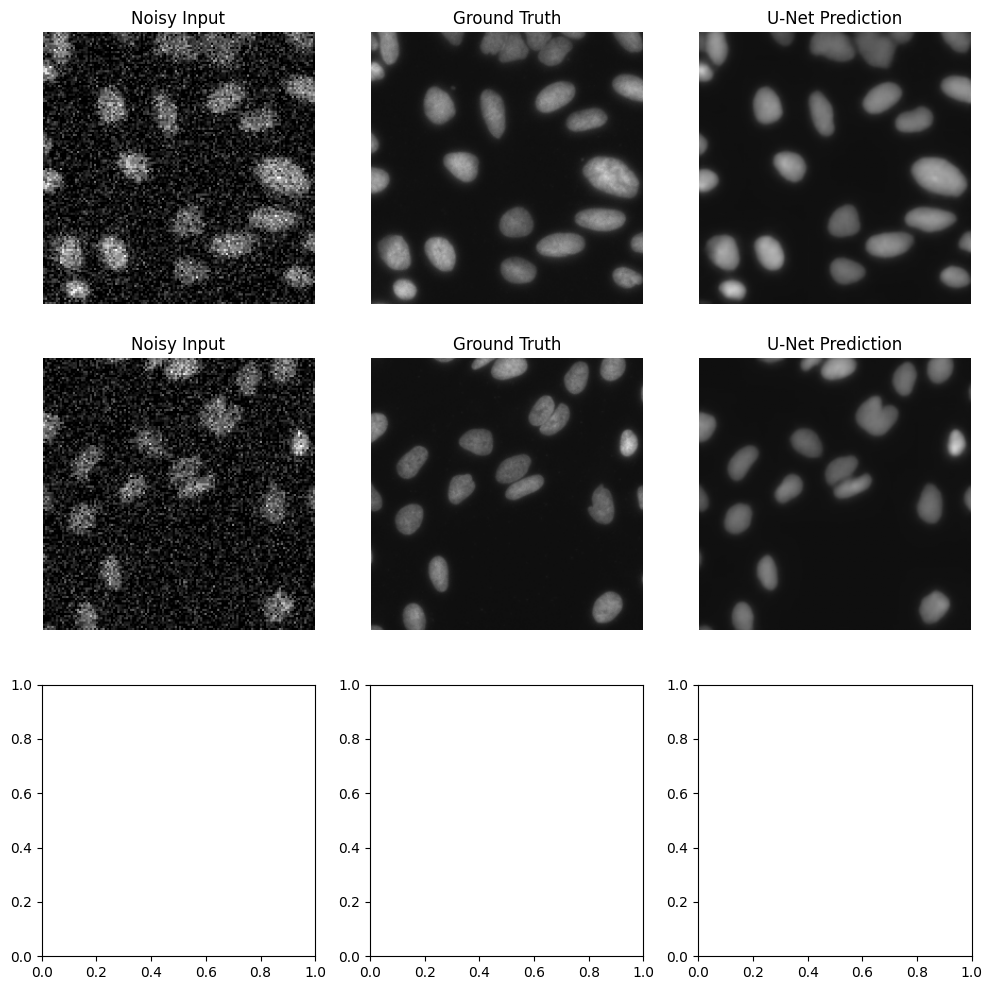

In [46]:
import matplotlib.pyplot as plt

model.eval()

noisy_batch, gt_batch = next(iter(test_loader))

noisy_batch = noisy_batch.to(device)
gt_batch = gt_batch.to(device)

with torch.no_grad():
    predictions = model(noisy_batch)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i in range(3):
    noisy_img = noisy_batch[i, 0].cpu().numpy()
    gt_img = gt_batch[i, 0].cpu().numpy()
    pred_img = predictions[i, 0].cpu().numpy()

    axes[i, 0].imshow(noisy_img, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title("Noisy Input")

    axes[i, 1].imshow(gt_img, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(pred_img, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("U-Net Prediction")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [47]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["PSNR", "SSIM"],
    "Value": [np.mean(all_psnr), np.mean(all_ssim)]
})

results.to_csv(
    "/content/drive/MyDrive/Microscopy-Denoising/standard_unet_results.csv",
    index=False
)

print(results)
print("Results saved successfully!")

  Metric      Value
0   PSNR  33.564546
1   SSIM   0.948840
Results saved successfully!


In [48]:
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/Microscopy-Denoising/checkpoints"
)

best_checkpoint = checkpoint_dir / "unet_best.pth"

print("E3 checkpoint exists:", best_checkpoint.exists())
print("Checkpoint size (MB):", round(best_checkpoint.stat().st_size / (1024**2), 2)
      if best_checkpoint.exists() else "Not found")

E3 checkpoint exists: True
Checkpoint size (MB): 118.39


In [49]:
print("Model:", "model" in globals())
print("Train loader:", "train_loader" in globals())
print("Validation loader:", "val_loader" in globals())
print("Device:", device if "device" in globals() else "Not found")

Model: True
Train loader: True
Validation loader: True
Device: cuda


In [50]:
import torch
import torch.nn as nn
import torch.nn.functional as F

def edge_loss(prediction, target):
    # Horizontal gradients
    pred_x = prediction[:, :, :, 1:] - prediction[:, :, :, :-1]
    target_x = target[:, :, :, 1:] - target[:, :, :, :-1]

    # Vertical gradients
    pred_y = prediction[:, :, 1:, :] - prediction[:, :, :-1, :]
    target_y = target[:, :, 1:, :] - target[:, :, :-1, :]

    loss_x = F.l1_loss(pred_x, target_x)
    loss_y = F.l1_loss(pred_y, target_y)

    return loss_x + loss_y


print("Edge loss function defined successfully!")

Edge loss function defined successfully!


In [51]:
criterion_l1 = nn.L1Loss()

lambda_edge = 0.1

def combined_loss(prediction, target):
    pixel_loss = criterion_l1(prediction, target)
    boundary_loss = edge_loss(prediction, target)

    total_loss = pixel_loss + lambda_edge * boundary_loss

    return total_loss

print("Combined loss defined successfully!")

Combined loss defined successfully!


In [52]:
import copy

model_e4 = copy.deepcopy(model)

# Freshly initialize all model weights
def reset_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        module.reset_parameters()

model_e4.apply(reset_weights)

model_e4 = model_e4.to(device)

optimizer_e4 = torch.optim.Adam(
    model_e4.parameters(),
    lr=0.001
)

print("E4 model initialized from scratch!")
print("E3 checkpoint remains untouched.")

E4 model initialized from scratch!
E3 checkpoint remains untouched.


In [53]:
EPOCHS_E4 = 10

train_losses_e4 = []
val_losses_e4 = []

best_val_loss_e4 = float("inf")

print("E4 Training Configuration")
print("Epochs:", EPOCHS_E4)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Loss: L1 + 0.1 * Edge Loss")
print("Device:", device)

E4 Training Configuration
Epochs: 10
Training batches: 860
Validation batches: 185
Loss: L1 + 0.1 * Edge Loss
Device: cuda


In [54]:
import time

for epoch in range(EPOCHS_E4):
    start_time = time.time()

    # Training
    model_e4.train()
    running_train_loss = 0.0

    for noisy, gt in train_loader:
        noisy = noisy.to(device)
        gt = gt.to(device)

        optimizer_e4.zero_grad()

        prediction = model_e4(noisy)
        loss = combined_loss(prediction, gt)

        loss.backward()
        optimizer_e4.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses_e4.append(epoch_train_loss)

    # Validation
    model_e4.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for noisy, gt in val_loader:
            noisy = noisy.to(device)
            gt = gt.to(device)

            prediction = model_e4(noisy)
            loss = combined_loss(prediction, gt)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses_e4.append(epoch_val_loss)

    epoch_time = (time.time() - start_time) / 60

    print(f"Epoch [{epoch+1}/{EPOCHS_E4}]")
    print(f"Train Loss: {epoch_train_loss:.6f}")
    print(f"Validation Loss: {epoch_val_loss:.6f}")
    print(f"Time: {epoch_time:.2f} minutes")

    if epoch_val_loss < best_val_loss_e4:
        best_val_loss_e4 = epoch_val_loss

        torch.save(
            model_e4.state_dict(),
            checkpoint_dir / "unet_edge_best.pth"
        )

        print("Best E4 model updated!")

    print("-" * 40)

Epoch [1/10]
Train Loss: 0.019478
Validation Loss: 0.014902
Time: 1.89 minutes
Best E4 model updated!
----------------------------------------
Epoch [2/10]
Train Loss: 0.015909
Validation Loss: 0.014429
Time: 1.87 minutes
Best E4 model updated!
----------------------------------------
Epoch [3/10]
Train Loss: 0.015140
Validation Loss: 0.013973
Time: 1.87 minutes
Best E4 model updated!
----------------------------------------
Epoch [4/10]
Train Loss: 0.014743
Validation Loss: 0.013996
Time: 1.87 minutes
----------------------------------------
Epoch [5/10]
Train Loss: 0.014323
Validation Loss: 0.014090
Time: 1.88 minutes
----------------------------------------
Epoch [6/10]
Train Loss: 0.014366
Validation Loss: 0.015033
Time: 1.87 minutes
----------------------------------------
Epoch [7/10]
Train Loss: 0.014153
Validation Loss: 0.013870
Time: 1.87 minutes
Best E4 model updated!
----------------------------------------
Epoch [8/10]
Train Loss: 0.014419
Validation Loss: 0.013477
Time: 1.

In [55]:
# E4 best checkpoint path
e4_checkpoint = checkpoint_dir / "unet_edge_best.pth"

print("E4 checkpoint exists:", e4_checkpoint.exists())

# Load best E4 weights
model_e4.load_state_dict(
    torch.load(e4_checkpoint, map_location=device)
)

model_e4.eval()

print("E4 best checkpoint loaded successfully!")

E4 checkpoint exists: True
E4 best checkpoint loaded successfully!


In [56]:
import numpy as np
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

model_e4.eval()

e4_psnr = []
e4_ssim = []

with torch.no_grad():
    for noisy_batch, gt_batch in test_loader:

        noisy_batch = noisy_batch.to(device)
        gt_batch = gt_batch.to(device)

        predictions = model_e4(noisy_batch)

        for i in range(predictions.shape[0]):

            pred_img = predictions[i, 0].cpu().numpy()
            gt_img = gt_batch[i, 0].cpu().numpy()

            psnr = peak_signal_noise_ratio(
                gt_img, pred_img, data_range=1.0
            )

            ssim = structural_similarity(
                gt_img, pred_img, data_range=1.0
            )

            e4_psnr.append(psnr)
            e4_ssim.append(ssim)

print("Test images evaluated:", len(e4_psnr))
print("E4 Average PSNR:", np.mean(e4_psnr))
print("E4 Average SSIM:", np.mean(e4_ssim))

Test images evaluated: 369
E4 Average PSNR: 33.18091113485603
E4 Average SSIM: 0.9448577723884984
